In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('/content/Reddit_Data.csv')
df.head()


,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [ ]:
df.shape

(37249, 2)

In [ ]:
df.sample()['clean_comment'].values

array([' this talking about this game the store which means these discussions while getting married the 570 4gb for their review '],
      dtype=object)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37249 entries, 0 to 37248
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   clean_comment  37149 non-null  object
 1   category       37249 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 582.1+ KB


In [ ]:
#identify some missing values
df.isnull().sum()

,0
clean_comment,100
category,0


In [ ]:
#show missing values
df[df['clean_comment'].isna()]

,clean_comment,category
413,NaN,0
605,NaN,0
2422,NaN,0
2877,NaN,0
3307,NaN,0
...,...,...
35975,NaN,0
36036,NaN,0
37043,NaN,0
37111,NaN,0


In [ ]:
df[df['clean_comment'].isna()]['category'].value_counts()

,count
category,
0,100


In [ ]:
#drop missing values
df.dropna(inplace=True)

In [ ]:
#check duplicate values
df.duplicated().sum()

np.int64(350)

In [ ]:
df[df.duplicated()]

,clean_comment,category
375,,0
392,,0
617,aurum mom,0
651,,0
1222,,0
...,...,...
36915,who won,0
37044,,0
37125,hari,0
37158,top kek,1


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#check whether have new line or not
df[(df['clean_comment'].str.strip()=='')]

,clean_comment,category
181,,0
4432,\n,0
10592,,0
16173,,0
32149,\n,0
34959,,0


In [ ]:
#new line consider as one row thats remove by that line
df=df[~(df['clean_comment'].str.strip()=='')]

In [ ]:
#convert the c'clean_comment'column to lowercase
df['clean_comment']=df['clean_comment'].str.lower()
#verify the transformation by displaying the first few rows
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [ ]:
#check there have or not empty space start and end of sentences
df[df['clean_comment'].apply(lambda x:x.endswith('') or x.startswith(''))]

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1
...,...,...
37244,jesus,0
37245,kya bhai pure saal chutiya banaya modi aur jab...,1
37246,downvote karna tha par upvote hogaya,0
37247,haha nice,1


In [ ]:
#to delete empty space from 'clean_comment' column
df['clean_comment']=df['clean_comment'].str.strip()

#verify remove empty spaces
df['clean_comment'].apply(lambda x:x.endswith('') or x.startswith('')).sum()


np.int64(36793)

In [ ]:
#to delete empty space from 'clean_comment' column
df['clean_comment']=df['clean_comment'].str.strip()

#verify remove empty spaces
df['clean_comment'].apply(lambda x:x.endswith('') or x.startswith('')).sum()


np.int64(36793)

In [ ]:
#identify comments containing URLs
url_pattern=r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'
comments_with_urls=df[df['clean_comment'].str.contains(url_pattern,regex=True)]

#display the comments containin URLs
comments_with_urls.head()

,clean_comment,category


In [ ]:
#check wheather have inside /n or not
comments_with_newline=df[df['clean_comment'].str.contains('\n')]

#display comments containing newlines
comments_with_newline.head()

,clean_comment,category
448,what missing jpg\nand why this brilliant edit ...,1
781,india has been ruined congress and populist sc...,-1
847,like aap for its stand corruption and making p...,-1
871,reduced trade\ndeficit stronger rupee aren the...,0
1354,amsa press conference australian maritime safe...,1


In [ ]:
#romove new line character/n for 'clean_comment'
df['clean_comment']=df['clean_comment'].str.replace('\n',' ',regex=True)

#verify the transformation by checking for any remaining new lines
comments_with_newline=df[df['clean_comment'].str.contains('\n')]
comments_with_newline

,clean_comment,category


EDA(Export Data Analysis

<Axes: xlabel='category', ylabel='count'>

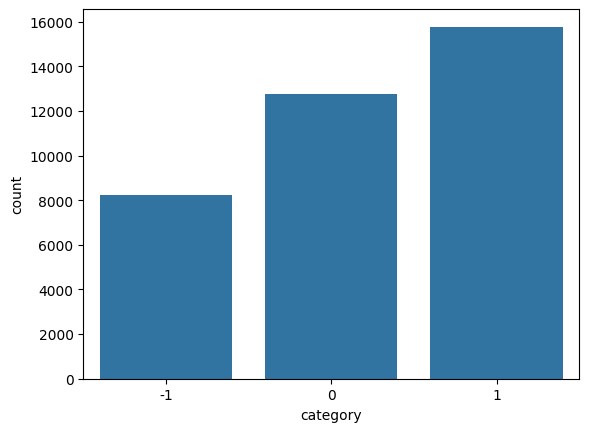

In [ ]:
#distribution of category classes(negative,netrual,positive)
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df,x="category")

In [ ]:
#percentage of classes
df['category'].value_counts(normalize=True).mul(100).round(2)

,proportion
category,
1,42.86
0,34.71
-1,22.42


In [ ]:
#create new column to count how many words have in one comment
df['word_count']=df['clean_comment'].apply(lambda x:len(x.split()))


In [ ]:
df.sample(5)

,clean_comment,category,word_count
20529,bas seena hai dear leader got clothes spine balls,0,9
8383,team standard nfl com eifert obviously out nee...,1,51
30173,300 blades grass were uprooted the bombs,0,7
17428,does anyone realize how pepe the frog has now ...,0,16
7443,india still has excellent submissions once eve...,1,9


In [ ]:
df['word_count'].describe()

,word_count
count,36793.000000
mean,29.667464
std,56.790738
min,1.000000
25%,6.000000
50%,13.000000
75%,30.000000
max,1307.000000


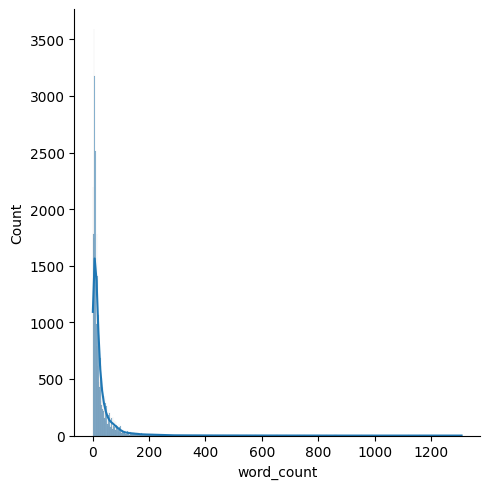

In [ ]:
sns.displot(df['word_count'],kde=True)